# Model comparison

Roadmap step 4, part 1. How well can a member's vote be predicted from earlier votes, and how much does each model add over the party line?

**Target:** whether a Democrat or Republican Yea or Nay goes against their own party's majority on that roll call. The party majority leaves the member out. A vote prediction follows: the party position, flipped when the predicted probability is above one half.

**What every model is given, from after the vote:**

- how both parties actually voted. This stands in for whip positions announced before the vote, which aren't in the data;
- which roll calls are kept. Near-unanimous roll calls (smaller side under 2.5%) are dropped, and that share is computed from the final vote. When the parties agree, the smaller side is mostly defectors, so a roll call where the parties agree is kept only if enough members defected. A member's own vote can decide whether a roll call just at the threshold is kept.

So these are predictions of **who breaks from a known party line on a contested roll call**, not of how a roll call will turn out.

**Periods:** train on 1991 to 2010, choose the number of trees and GRU epochs on 2011 to 2014, and test once on 2015 to 2024. History features and GRU states start in 1981.

**Models:** see the [problem README](../docs/README.md). Each is compared with everyone voting with their party, as the analysis rules require, and results are given separately for party-opposed roll calls and for defections. The GRU is shown as single seeds, mainly seed 0, so it is compared like for like with the one boosting model.

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, log_loss, roc_auc_score

warnings.filterwarnings("ignore")
COLORS = {"D": "#2a78d6", "R": "#c93b3b"}
NEUTRAL = "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b5b4ad",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "text.color": "#0b0b0b", "xtick.color": NEUTRAL, "ytick.color": NEUTRAL,
    "legend.frameon": False,
})
OUTPUTS = Path.cwd().parent / "outputs"
MODEL_COLORS = {"logistic": "#2a78d6", "boosting": "#eb6834", "gru": "#1baf7a"}
NAMES = {
    "party_line": "Everyone votes with their party", "training_rate": "Training-period defection rate",
    "own_past_rate": "Own past rate on this kind of vote", "logistic": "Logistic regression",
    "boosting": "Gradient boosting", "gru_seed0": "GRU, seed 0", "gru_seed1": "GRU, seed 1", "gru_seed2": "GRU, seed 2",
    "gru_mean": "GRU, average of 3 seeds", "boosting_with_split": "Gradient boosting + party split sizes (after the vote)",
}
predictions = pd.read_parquet(OUTPUTS / "predictions.parquet")
predictions["p_gru_mean"] = predictions[["p_gru_seed0", "p_gru_seed1", "p_gru_seed2"]].mean(axis=1)
predictions["defected"] = predictions["defected"].astype(bool)
run_log = (OUTPUTS / "run_log.txt").read_text(encoding="utf-8").splitlines()
print("Model choices on the validation years:")
print("\n".join(line for line in run_log if "best number of trees" in line or "epoch" in line))
test = predictions[predictions["split"] == "test"]
valid = predictions[predictions["split"] == "validation"]
for name, part in [("Validation, 2011 to 2014", valid), ("Test, 2015 to 2024", test)]:
    print(f"{name}: {len(part):,} votes on {part[['congress', 'chamber', 'rollnumber']].drop_duplicates().shape[0]:,} roll calls, "
          f"{part['person'].nunique():,} members; defection rate {part['defected'].mean():.4f}, "
          f"{part['party_opposed'].mean():.1%} of votes on party-opposed roll calls")


Model choices on the validation years:
boosting: best number of trees 284 of 600, validation log loss 0.2427
boosting+split: best number of trees 407 of 600, validation log loss 0.1795
seed 0 epoch 1: train log loss 0.3331, validation log loss 0.2524
seed 0 epoch 2: train log loss 0.3020, validation log loss 0.2403
seed 0 epoch 3: train log loss 0.2925, validation log loss 0.2392
seed 0 epoch 4: train log loss 0.2888, validation log loss 0.2370
seed 0 epoch 5: train log loss 0.2855, validation log loss 0.2367
seed 0 epoch 6: train log loss 0.2827, validation log loss 0.2362
seed 0 epoch 7: train log loss 0.2802, validation log loss 0.2355
seed 0 epoch 8: train log loss 0.2784, validation log loss 0.2350
seed 0 epoch 9: train log loss 0.2761, validation log loss 0.2439
seed 0 epoch 10: train log loss 0.2747, validation log loss 0.2369
seed 1 epoch 1: train log loss 0.3322, validation log loss 0.2581
seed 1 epoch 2: train log loss 0.3063, validation log loss 0.2482
seed 1 epoch 3: train 

Validation, 2011 to 2014: 1,112,609 votes on 3,417 roll calls, 646 members; defection rate 0.0906, 82.7% of votes on party-opposed roll calls
Test, 2015 to 2024: 2,319,540 votes on 8,027 roll calls, 883 members; defection rate 0.0638, 80.2% of votes on party-opposed roll calls


**What this shows**

- **Defection is rare and falling.** 6.4% of test votes break from the party, against 9.1% on validation years and 11.7% on training years. Every trained model learned from a higher rate, so calibration on later years is a real test.
- **80% of test votes are on party-opposed roll calls,** where the two party majorities voted on opposite sides. The rest are roll calls where the parties agree (or one is tied). There, defecting means voting against both parties.
- **Model choices stopped early.** Boosting kept 284 of 600 trees. The GRU's best epoch was the 5th to 8th, depending on the seed, chosen by validation log loss. Validation loss bounced (seed 0 rose from 0.2350 to 0.2439 in one epoch), so the stopping point is somewhat noisy.

## How do the models compare on the test years?

In [2]:
def metrics(part, column):
    y, p = part["defected"].to_numpy(), part[column].to_numpy()
    flipped = p > 0.5
    k = int(y.sum())
    top = np.zeros(len(p), dtype=bool)
    top[np.argsort(-p, kind="stable")[:k]] = True
    opposed = part["party_opposed"].to_numpy()
    return {
        "accuracy, all votes": np.mean(flipped == y),
        "accuracy, party-opposed": np.mean((flipped == y)[opposed]),
        "defection AUC": roc_auc_score(y, p) if np.ptp(p) > 0 else 0.5,
        "average precision": average_precision_score(y, p),
        "log loss": log_loss(y, np.clip(p, 1e-6, 1 - 1e-6)),
        "defections caught at 0.5": (flipped & y).sum() / k,
        "precision at 0.5": (flipped & y).sum() / max(flipped.sum(), 1),
        "caught when flagging as many as defect": (top & y).sum() / k,
        "mean prediction": p.mean(),
    }


ORDER = ["party_line", "training_rate", "own_past_rate", "logistic", "boosting", "gru_seed0", "gru_seed1", "gru_seed2", "gru_mean",
         "boosting_with_split"]


def table(part):
    return pd.DataFrame({NAMES[m]: metrics(part, f"p_{m}") for m in ORDER}).T


print(f"Test, 2015 to 2024. Defection rate {test['defected'].mean():.4f}; a model with no information has average precision equal to it.")
display(table(test).round(4))
print("Validation, 2011 to 2014 (used to choose the number of trees and GRU epochs):")
display(table(valid)[["accuracy, all votes", "defection AUC", "average precision", "log loss"]].round(4))
for chamber in ["House", "Senate"]:
    part = test[test["chamber"] == chamber]
    print(f"Test, {chamber}: {len(part):,} votes, defection rate {part['defected'].mean():.4f}")
    display(table(part)[["accuracy, all votes", "accuracy, party-opposed", "defection AUC", "average precision",
                         "caught when flagging as many as defect"]].round(4))


Test, 2015 to 2024. Defection rate 0.0638; a model with no information has average precision equal to it.


,"accuracy, all votes","accuracy, party-opposed",defection AUC,average precision,log loss,defections caught at 0.5,precision at 0.5,caught when flagging as many as defect,mean prediction
Everyone votes with their party,0.9362,0.9528,0.5000,0.0638,0.8820,0.0000,0.0000,0.0611,0.0000
Training-period defection rate,0.9362,0.9528,0.5000,0.0638,0.2534,0.0000,0.0000,0.0611,0.1168
Own past rate on this kind of vote,0.9380,0.9528,0.7734,0.2695,0.2059,0.0627,0.6499,0.3133,0.0713
Logistic regression,0.9396,0.9540,0.8305,0.3622,0.1880,0.1379,0.6226,0.3993,0.0778
Gradient boosting,0.9400,0.9547,0.8497,0.3794,0.1783,0.1388,0.6404,0.4108,0.0693
"GRU, seed 0",0.9418,0.9555,0.8542,0.4091,0.1742,0.1910,0.6490,0.4304,0.0635
"GRU, seed 1",0.9411,0.9552,0.8575,0.4005,0.1738,0.1688,0.6470,0.4308,0.0648
"GRU, seed 2",0.9414,0.9556,0.8562,0.4070,0.1749,0.1643,0.6661,0.4289,0.0708
"GRU, average of 3 seeds",0.9420,0.9558,0.8622,0.4207,0.1717,0.1726,0.6788,0.4396,0.0664
Gradient boosting + party split sizes (after the vote),0.9492,0.9616,0.9529,0.6084,0.1225,0.3779,0.6861,0.5722,0.0556


Validation, 2011 to 2014 (used to choose the number of trees and GRU epochs):


,"accuracy, all votes",defection AUC,average precision,log loss
Everyone votes with their party,0.9094,0.5000,0.0906,1.2513
Training-period defection rate,0.9094,0.5000,0.0906,0.3074
Own past rate on this kind of vote,0.9096,0.7424,0.2511,0.2738
Logistic regression,0.9117,0.8073,0.3345,0.2502
Gradient boosting,0.9130,0.8190,0.3572,0.2427
"GRU, seed 0",0.9142,0.8368,0.3919,0.2350
"GRU, seed 1",0.9145,0.8384,0.3967,0.2334
"GRU, seed 2",0.9139,0.8311,0.3839,0.2368
"GRU, average of 3 seeds",0.9148,0.8415,0.4021,0.2319
Gradient boosting + party split sizes (after the vote),0.9233,0.9259,0.5625,0.1795


Test, House: 2,023,501 votes, defection rate 0.0619


,"accuracy, all votes","accuracy, party-opposed",defection AUC,average precision,caught when flagging as many as defect
Everyone votes with their party,0.9381,0.9545,0.5000,0.0619,0.0605
Training-period defection rate,0.9381,0.9545,0.5000,0.0619,0.0605
Own past rate on this kind of vote,0.9401,0.9545,0.7708,0.2684,0.3109
Logistic regression,0.9413,0.9554,0.8289,0.3545,0.3918
Gradient boosting,0.9419,0.9562,0.8478,0.3746,0.4071
"GRU, seed 0",0.9430,0.9564,0.8501,0.3947,0.4177
"GRU, seed 1",0.9427,0.9564,0.8542,0.3922,0.4243
"GRU, seed 2",0.9428,0.9564,0.8524,0.3949,0.4188
"GRU, average of 3 seeds",0.9434,0.9567,0.8585,0.4084,0.4290
Gradient boosting + party split sizes (after the vote),0.9498,0.9620,0.9524,0.5951,0.5624


Test, Senate: 296,039 votes, defection rate 0.0769


,"accuracy, all votes","accuracy, party-opposed",defection AUC,average precision,caught when flagging as many as defect
Everyone votes with their party,0.9231,0.9401,0.5000,0.0769,0.0644
Training-period defection rate,0.9231,0.9401,0.5000,0.0769,0.0644
Own past rate on this kind of vote,0.9234,0.9401,0.7844,0.2720,0.3247
Logistic regression,0.9285,0.9441,0.8376,0.4037,0.4390
Gradient boosting,0.9277,0.9438,0.8576,0.4066,0.4261
"GRU, seed 0",0.9334,0.9491,0.8761,0.4881,0.4987
"GRU, seed 1",0.9297,0.9461,0.8757,0.4581,0.4677
"GRU, seed 2",0.9317,0.9491,0.8771,0.4740,0.4848
"GRU, average of 3 seeds",0.9325,0.9494,0.8824,0.4881,0.4944
Gradient boosting + party split sizes (after the vote),0.9456,0.9587,0.9562,0.6786,0.6264


**What this shows**

- **Accuracy barely moves, because the party line is already right 93.6% of the time** (95.3% on party-opposed roll calls). Single GRU seeds reach 94.1% to 94.2% and 95.5% to 95.6%. On accuracy alone, prediction looks almost solved and models look useless. Neither is true, so the useful measures are ranking (AUC) and average precision, which is 0.064 for a model with no information.
- **Each step up the ladder adds information on the test years:**

  | Model | AUC | Average precision | Defections caught when flagging 6.4% of votes |
  |---|---|---|---|
  | Own past rate on this kind of vote | 0.773 | 0.270 | 31% |
  | Logistic regression | 0.831 | 0.362 | 40% |
  | Gradient boosting | 0.850 | 0.379 | 41% |
  | GRU, single seeds | 0.854 to 0.858 | 0.401 to 0.409 | 43% |
  | Gradient boosting + party split sizes (after the vote) | 0.953 | 0.608 | 57% |

- **The member's own record carries most of the signal.** A rate with no fitting at all reaches an AUC of 0.773. Fitted models add roll-call context: vote type, which side the party took, and how history interacts with whether the roll call is party-opposed.
- **At the 0.5 threshold, models flag few votes, but those flags are mostly right.** Single GRU seeds catch 16% to 19% of defections at 65% to 67% precision. Most defections never look more likely than not beforehand.
- **The split-size variant is an upper reference, not a forecast.** It knows how split each party was, which counts the defectors in the member's own party. A fully united party means nobody defected, so this partly contains the answer. Its AUC of 0.953 doesn't show how much of what remains is about the roll call rather than the member.
- **The Senate gains more from the GRU than the House.** Senate average precision is 0.458 to 0.488 for single GRU seeds against 0.407 for boosting. House: 0.392 to 0.395 against 0.375. In the Senate, logistic regression and boosting are close.
- **Trained models predict too much defection overall, logistic regression most.** It averages 7.8% against an actual 6.4%, boosting 6.9%, single GRU seeds 6.4% to 7.1%.

## Are the differences larger than chance?

In [3]:
# Votes cluster by roll call (shared circumstances) and by member (persistent habits), so each draw resamples both:
# a vote's weight is its roll call's draw count times its member's draw count (a two-way pigeonhole bootstrap).
# Single GRU seeds are compared with the single boosting model, so the comparison is like for like.


class Ranked:
    """Weighted AUC and average precision from one sort; equal to sklearn's with sample_weight, ties included."""

    def __init__(self, p, y):
        values, self.group = np.unique(-p, return_inverse=True)
        self.n, self.y = len(values), y

    def scores(self, w):
        pos = np.bincount(self.group, weights=w * self.y, minlength=self.n)
        neg = np.bincount(self.group, weights=w * (1 - self.y), minlength=self.n)
        tp, fp = np.cumsum(pos), np.cumsum(neg)
        auc = (pos * (fp[-1] - fp) + 0.5 * pos * neg).sum() / (tp[-1] * fp[-1])
        ap = (pos / tp[-1] * tp / np.maximum(tp + fp, 1e-300)).sum()
        return auc, ap


PAIRS = [("gru_seed0", "boosting"), ("gru_seed1", "boosting"), ("gru_seed2", "boosting"), ("boosting", "logistic"),
         ("gru_seed0", "logistic"), ("logistic", "own_past_rate"), ("boosting_with_split", "boosting")]
REPS = 1000


def bootstrap(part, title, show_models=False):
    rng = np.random.default_rng(0)
    y = part["defected"].to_numpy().astype(float)
    rollcall = part.groupby(["congress", "chamber", "rollnumber"]).ngroup().to_numpy()
    member = part.groupby("person").ngroup().to_numpy()
    n_rollcalls, n_members = rollcall.max() + 1, member.max() + 1
    models = sorted({m for pair in PAIRS for m in pair})
    ranked = {m: Ranked(part[f"p_{m}"].to_numpy(), y) for m in models}
    point = {m: ranked[m].scores(np.ones(len(y))) for m in models}
    draws = {m: [] for m in models}
    for _ in range(REPS):
        w = (np.bincount(rng.integers(0, n_rollcalls, n_rollcalls), minlength=n_rollcalls)[rollcall]
             * np.bincount(rng.integers(0, n_members, n_members), minlength=n_members)[member]).astype(float)
        for m in models:
            draws[m].append(ranked[m].scores(w))
    draws = {m: np.array(v) for m, v in draws.items()}
    rows = []
    for a, b in PAIRS:
        diff = draws[a] - draws[b]
        low, high = np.percentile(diff, [2.5, 97.5], axis=0)
        rows.append({"comparison": f"{NAMES[a]} minus {NAMES[b]}",
                     "AUC difference": point[a][0] - point[b][0], "AUC 95% low": low[0], "AUC 95% high": high[0],
                     "AP difference": point[a][1] - point[b][1], "AP 95% low": low[1], "AP 95% high": high[1]})
    print(f"{title}: differences with 95% intervals from {REPS} draws resampling roll calls and members together")
    display(pd.DataFrame(rows).set_index("comparison").round(4))
    if show_models:
        print("Each model alone, with the same intervals:")
        display(pd.DataFrame({NAMES[m]: {"AUC": point[m][0], "AUC 95% low": np.percentile(draws[m][:, 0], 2.5),
                                         "AUC 95% high": np.percentile(draws[m][:, 0], 97.5), "AP": point[m][1],
                                         "AP 95% low": np.percentile(draws[m][:, 1], 2.5), "AP 95% high": np.percentile(draws[m][:, 1], 97.5)}
                              for m in models}).T.round(4))


bootstrap(test, "All test votes", show_models=True)
bootstrap(test[test["party_opposed"]], "Party-opposed roll calls")
bootstrap(test[~test["party_opposed"]], "Roll calls where the parties agree or one is tied")
seeds = pd.DataFrame({s: metrics(test, f"p_gru_seed{s}") for s in range(3)}).T
print("Spread across GRU seeds (standard deviation over 3 seeds):")
display(seeds[["defection AUC", "average precision", "log loss"]].std().round(4).to_frame("sd"))

All test votes: differences with 95% intervals from 1000 draws resampling roll calls and members together


,AUC difference,AUC 95% low,AUC 95% high,AP difference,AP 95% low,AP 95% high
comparison,,,,,,
"GRU, seed 0 minus Gradient boosting",0.0045,0.0014,0.0075,0.0297,0.0218,0.0387
"GRU, seed 1 minus Gradient boosting",0.0078,0.0052,0.0106,0.0211,0.0137,0.0293
"GRU, seed 2 minus Gradient boosting",0.0065,0.0039,0.0093,0.0276,0.0202,0.0361
Gradient boosting minus Logistic regression,0.0192,0.0158,0.0226,0.0172,0.0105,0.0237
"GRU, seed 0 minus Logistic regression",0.0237,0.0194,0.0282,0.0469,0.0371,0.0578
Logistic regression minus Own past rate on this kind of vote,0.0571,0.0490,0.0667,0.0927,0.0823,0.1033
Gradient boosting + party split sizes (after the vote) minus Gradient boosting,0.1032,0.0946,0.1120,0.2290,0.2159,0.2423


Each model alone, with the same intervals:


,AUC,AUC 95% low,AUC 95% high,AP,AP 95% low,AP 95% high
Gradient boosting,0.8497,0.8396,0.8590,0.3794,0.3545,0.4039
Gradient boosting + party split sizes (after the vote),0.9529,0.9505,0.9553,0.6084,0.5884,0.6283
"GRU, seed 0",0.8542,0.8446,0.8635,0.4091,0.3841,0.4348
"GRU, seed 1",0.8575,0.8482,0.8661,0.4005,0.3761,0.4261
"GRU, seed 2",0.8562,0.8467,0.8652,0.4070,0.3824,0.4329
Logistic regression,0.8305,0.8200,0.8406,0.3622,0.3363,0.3866
Own past rate on this kind of vote,0.7734,0.7609,0.7849,0.2695,0.2411,0.2963


Party-opposed roll calls: differences with 95% intervals from 1000 draws resampling roll calls and members together


,AUC difference,AUC 95% low,AUC 95% high,AP difference,AP 95% low,AP 95% high
comparison,,,,,,
"GRU, seed 0 minus Gradient boosting",0.0015,-0.0022,0.0056,0.0187,0.0090,0.0280
"GRU, seed 1 minus Gradient boosting",0.0043,0.0010,0.0078,0.0164,0.0078,0.0245
"GRU, seed 2 minus Gradient boosting",0.0062,0.0032,0.0094,0.0252,0.0171,0.0334
Gradient boosting minus Logistic regression,0.0339,0.0284,0.0401,0.0375,0.0297,0.0450
"GRU, seed 0 minus Logistic regression",0.0354,0.0290,0.0427,0.0562,0.0445,0.0679
Logistic regression minus Own past rate on this kind of vote,0.0691,0.0570,0.0817,0.1337,0.1195,0.1478
Gradient boosting + party split sizes (after the vote) minus Gradient boosting,0.1234,0.1108,0.1374,0.2821,0.2656,0.2993


Roll calls where the parties agree or one is tied: differences with 95% intervals from 1000 draws resampling roll calls and members together


,AUC difference,AUC 95% low,AUC 95% high,AP difference,AP 95% low,AP 95% high
comparison,,,,,,
"GRU, seed 0 minus Gradient boosting",0.0179,0.0111,0.0253,0.0494,0.0353,0.0633
"GRU, seed 1 minus Gradient boosting",0.0248,0.0187,0.0316,0.0500,0.0380,0.0625
"GRU, seed 2 minus Gradient boosting",0.0153,0.0090,0.0214,0.0364,0.0229,0.0498
Gradient boosting minus Logistic regression,-0.0069,-0.0132,-0.0009,-0.0065,-0.0165,0.0046
"GRU, seed 0 minus Logistic regression",0.0110,0.0035,0.0189,0.0429,0.0260,0.0615
Logistic regression minus Own past rate on this kind of vote,0.0427,0.0363,0.0499,0.0513,0.0424,0.0608
Gradient boosting + party split sizes (after the vote) minus Gradient boosting,0.1058,0.0957,0.1178,0.1983,0.1804,0.2192


Spread across GRU seeds (standard deviation over 3 seeds):


,sd
defection AUC,0.0017
average precision,0.0045
log loss,0.0006


**What this shows**

Each draw resamples roll calls and members together, because votes cluster both ways. Differences are paired: both models are scored on the same resampled votes, so the interval of a difference is much narrower than the intervals of either model alone.

- **On all test votes together, every step in the ladder is larger than chance:**
  - logistic regression over own past rate: AUC +0.057 (0.049 to 0.067), average precision +0.093;
  - boosting over logistic regression: AUC +0.019 (0.016 to 0.023), average precision +0.017 (0.011 to 0.024);
  - each single GRU seed over boosting: AUC +0.005 to +0.008 (lowest bound 0.0014), average precision +0.021 to +0.030 (lowest bound 0.014).
- **On party-opposed roll calls, the GRU's gain over boosting is smaller.** Average precision gains are +0.016 to +0.025, all above zero. On AUC, seed 0's gain (+0.0015) can't be told from zero (-0.002 to +0.006); seeds 1 and 2 are just above it. Boosting's gain over logistic regression is larger here (AUC +0.034, AP +0.038).
- **On roll calls where the parties agree, boosting is no better than logistic regression,** slightly worse on AUC (-0.007, -0.013 to -0.001). The GRU beats both (AP +0.036 to +0.050 over boosting).
- **So the GRU's gain is real but modest,** larger for ranking the likeliest defections (AP, about 6% to 8% of boosting's) than for overall ranking (AUC, under 1%), and largest on roll calls where the parties agree.
- **Seed noise is smaller than the gain.** Across 3 seeds, AUC varies by 0.002 and average precision by 0.005 (standard deviations).
- **Limits of this comparison:**
  - Boosting's settings other than the number of trees weren't tuned, and neither were the GRU's. A tuned boosting model could narrow the gap. Only one boosting fit was made, so its seed variation isn't included.
  - The GRU sees the member's full sequence, while boosting sees nine hand-built summaries of it. The gain shows the summaries miss something, not that a recurrent model is needed to capture it.
  - One time split: intervals cover resampling within 2015 to 2024, not a different future.

## Performance by Congress

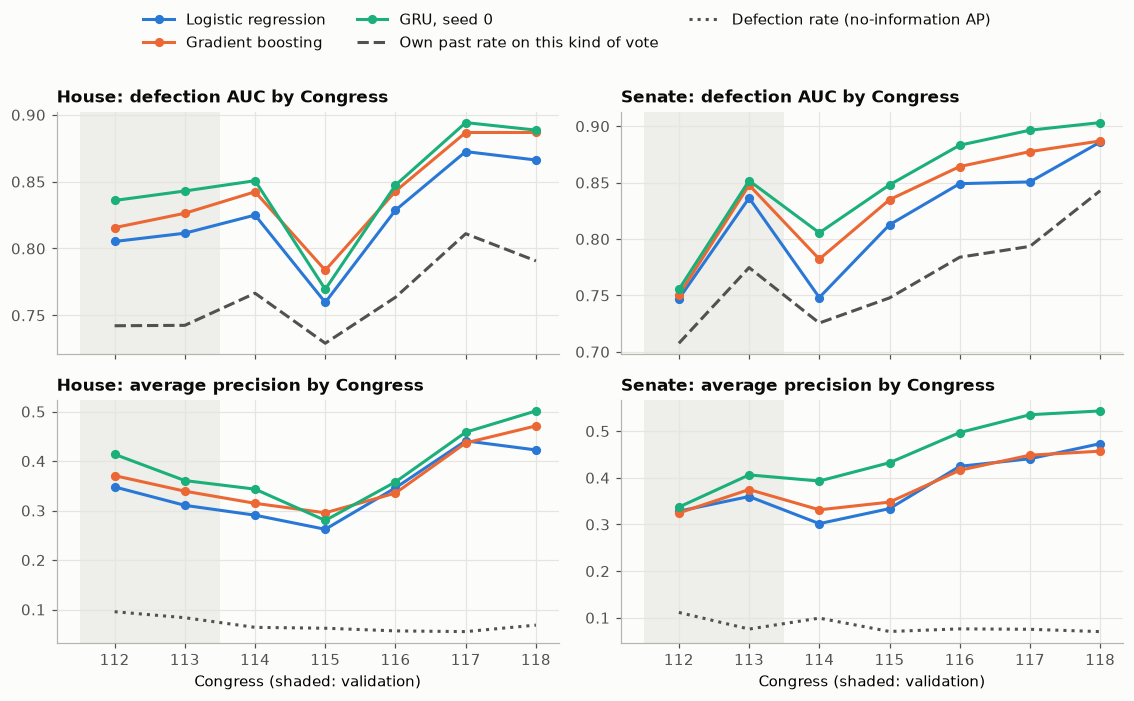

votes  defection rate  AUC logistic  AUC boosting  \
chamber congress                                                         
House   112       597287.0          0.0956        0.8052        0.8156   
        113       424800.0          0.0834        0.8114        0.8264   
        114       469959.0          0.0639        0.8250        0.8424   
        115       395888.0          0.0622        0.7597        0.7837   
        116       337316.0          0.0568        0.8287        0.8428   
        117       354861.0          0.0553        0.8725        0.8868   
        118       465477.0          0.0684        0.8662        0.8868   
Senate  112        38899.0          0.1114        0.7470        0.7503   
        113        51623.0          0.0758        0.8364        0.8478   
        114        39428.0          0.0992        0.7481        0.7822   
        115        49481.0          0.0706        0.8126        0.8349   
        116        61773.0          0.0762        0.8490        0.8642   
        117        84945.0          0.0753        0.8506        0.8775   
        118        60412.0          0.0703        0.8859        0.8869   

                  AUC gru  mean prediction logistic  mean prediction boosting  \
chamber congress                                                                
House   112        0.8359                    0.1024                    0.1000   
        113        0.8430                    0.0862                    0.0832   
        114        0.8507                    0.0733                    0.0688   
        115        0.7695                    0.0627                    0.0533   
        116        0.8474                    0.0755                    0.0660   
        117        0.8942                    0.0792                    0.0662   
        118        0.8886                    0.0871                    0.0779   
Senate  112        0.7553                    0.1218                    0.1133   
        113        0.8517                    0.0899                    0.0820   
        114        0.8055                    0.1026                    0.0934   
        115        0.8480                    0.0861                    0.0792   
        116        0.8832                    0.0899                    0.0825   
        117        0.8964                    0.0892                    0.0848   
        118        0.9032                    0.0954                    0.0883   

                  mean prediction gru  
chamber congress                       
House   112                    0.0871  
        113                    0.0728  
        114                    0.0627  
        115                    0.0548  
        116                    0.0618  
        117                    0.0568  
        118                    0.0722  
Senate  112                    0.1032  
        113                    0.0757  
        114                    0.0841  
        115                    0.0658  
        116                    0.0654  
        117                    0.0754  
        118                    0.0740

In [4]:
both = pd.concat([valid, test])
# Single GRU seed against the single boosting model, like for like.
MAIN = {"logistic": "logistic", "boosting": "boosting", "gru": "gru_seed0"}
fig, axes = plt.subplots(2, 2, figsize=(10.5, 6.4), sharex=True)
for column, chamber in enumerate(["House", "Senate"]):
    part = both[both["chamber"] == chamber]
    for label, model in MAIN.items():
        by = part.groupby("congress").apply(lambda g: pd.Series({
            "auc": roc_auc_score(g["defected"], g[f"p_{model}"]), "ap": average_precision_score(g["defected"], g[f"p_{model}"])}))
        axes[0, column].plot(by.index, by["auc"], marker="o", markersize=5, color=MODEL_COLORS[label], label=NAMES[model])
        axes[1, column].plot(by.index, by["ap"], marker="o", markersize=5, color=MODEL_COLORS[label], label=NAMES[model])
    own = part.groupby("congress").apply(lambda g: roc_auc_score(g["defected"], g["p_own_past_rate"]))
    axes[0, column].plot(own.index, own, color=NEUTRAL, linestyle="--", label=NAMES["own_past_rate"])
    rate = part.groupby("congress")["defected"].mean()
    axes[1, column].plot(rate.index, rate, color=NEUTRAL, linestyle=":", label="Defection rate (no-information AP)")
    axes[0, column].set_title(f"{chamber}: defection AUC by Congress")
    axes[1, column].set_title(f"{chamber}: average precision by Congress")
    for row in range(2):
        axes[row, column].axvspan(111.5, 113.5, color="#e6e5df", alpha=0.6, lw=0)
axes[1, 0].set_xlabel("Congress (shaded: validation)")
axes[1, 1].set_xlabel("Congress (shaded: validation)")
handles, labels = axes[0, 0].get_legend_handles_labels()
handles2, labels2 = axes[1, 0].get_legend_handles_labels()
fig.legend(handles + handles2[-1:], labels + labels2[-1:], loc="upper center", ncol=3)
fig.tight_layout(rect=(0, 0, 1, 0.9))
plt.show()
by_congress = both.groupby(["chamber", "congress"]).apply(lambda g: pd.Series({
    "votes": len(g), "defection rate": g["defected"].mean(),
    **{f"AUC {label}": roc_auc_score(g["defected"], g[f"p_{m}"]) for label, m in MAIN.items()},
    **{f"mean prediction {label}": g[f"p_{m}"].mean() for label, m in MAIN.items()}}))
display(by_congress.round(4))


**What this shows**

The GRU here is seed 0.

- **In the Senate, the GRU leads in every test Congress,** and its lead grows: average precision 0.54 in the 118th Congress against 0.46 for boosting, AUC 0.903 against 0.887.
- **In the House, the GRU's lead is small and not consistent.** Its AUC is below boosting's in the 115th Congress (0.770 against 0.784) and about equal in the 116th and 118th. On average precision it leads in every House Congress except the 115th.
- **Every fitted model beats the member's own past rate in every Congress.** Boosting leads logistic regression on AUC throughout, but their average precision is close from 2019 on.
- **The 115th House (2017 to 2018) is hard for every model.** AUC falls to 0.76 to 0.78 and average precision to 0.26 to 0.30. Why isn't established here.
- **Ranking gets easier later in the test period.** House AUC rises from 0.85 to 0.89 and Senate AUC from 0.81 to 0.90 between the 114th and 118th Congresses. That is the opposite of the usual decay as the test period moves away from training. One possible reason, not tested here, is that defection became concentrated in fewer, more consistent members.
- **Mean predictions follow the falling rate imperfectly.** In the 117th House the GRU averages 5.7% against an actual 5.5%, logistic regression 7.9%. Only the 2011 to 2014 validation period was used to choose when to stop, so this tracking isn't tuned to the test years.
- The 112th Senate (2011 to 2012), a validation Congress, is the weakest period for every model (AUC 0.75 to 0.76).

## Calibration

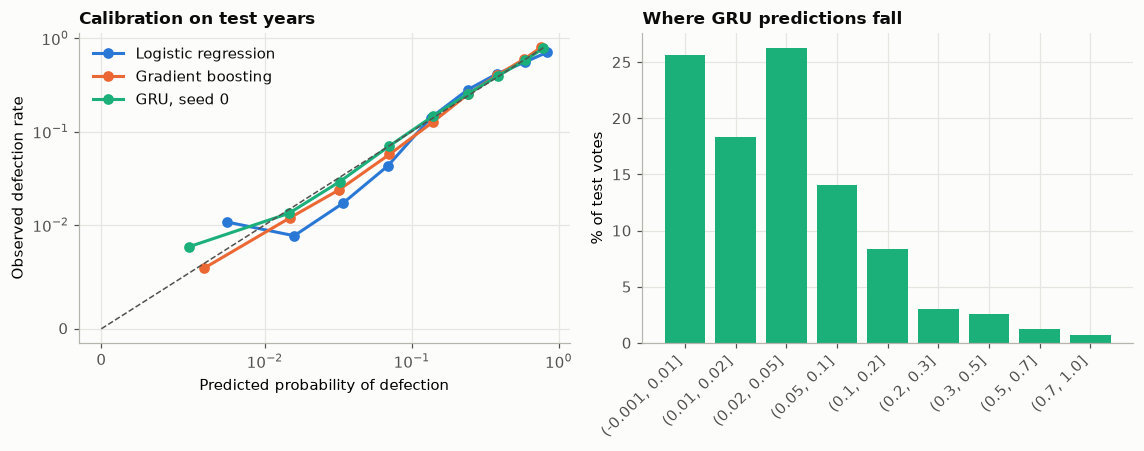

logistic                   boosting                   \
               predicted observed   votes predicted observed   votes   
(-0.001, 0.01]    0.0077   0.0107   29323    0.0063   0.0058  394205   
(0.01, 0.02]      0.0159   0.0090  231976    0.0148   0.0119  452498   
(0.02, 0.05]      0.0340   0.0170  884362    0.0322   0.0238  642122   
(0.05, 0.1]       0.0686   0.0427  745679    0.0707   0.0570  377920   
(0.1, 0.2]        0.1357   0.1415  279432    0.1405   0.1275  263140   
(0.2, 0.3]        0.2418   0.2814   69345    0.2422   0.2519   92329   
(0.3, 0.5]        0.3808   0.4148   46616    0.3819   0.4017   65238   
(0.5, 0.7]        0.5881   0.5530   18010    0.5861   0.6002   25531   
(0.7, 1.0]        0.8391   0.7073   14797    0.7613   0.7970    6557   

                     gru                   
               predicted observed   votes  
(-0.001, 0.01]    0.0054   0.0079  594702  
(0.01, 0.02]      0.0146   0.0133  424878  
(0.02, 0.05]      0.0323   0.0290  609089  
(0.05, 0.1]       0.0703   0.0697  325357  
(0.1, 0.2]        0.1393   0.1458  193626  
(0.2, 0.3]        0.2438   0.2553   69242  
(0.3, 0.5]        0.3848   0.3925   59059  
(0.5, 0.7]        0.5907   0.5788   28206  
(0.7, 1.0]        0.7880   0.7776   15381

In [5]:
bins = np.array([0, 0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 1.0])
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
rows = {}
for label, model in MAIN.items():
    p = test[f"p_{model}"]
    groups = pd.cut(p, bins, include_lowest=True)
    curve = test.groupby(groups, observed=True).agg(predicted=(f"p_{model}", "mean"), observed=("defected", "mean"), votes=("defected", "size"))
    rows[label] = curve
    axes[0].plot(curve["predicted"], curve["observed"], marker="o", markersize=6, color=MODEL_COLORS[label], label=NAMES[model])
axes[0].plot([0, 0.8], [0, 0.8], color=NEUTRAL, linestyle="--", linewidth=1)
axes[0].set_xscale("symlog", linthresh=0.01)
axes[0].set_yscale("symlog", linthresh=0.01)
axes[0].set_xlabel("Predicted probability of defection")
axes[0].set_ylabel("Observed defection rate")
axes[0].set_title("Calibration on test years")
axes[0].legend()
counts = rows["gru"]["votes"]
axes[1].bar(range(len(counts)), counts / counts.sum() * 100, color=MODEL_COLORS["gru"], width=0.8)
axes[1].set_xticks(range(len(counts)), [str(i) for i in counts.index], rotation=45, ha="right")
axes[1].set_ylabel("% of test votes")
axes[1].set_title("Where GRU predictions fall")
fig.tight_layout()
plt.show()
display(pd.concat(rows, axis=1).round(4))


**What this shows**

The GRU here is seed 0.

- **The GRU is closest to calibrated:** within about one point in every bin from 1% to 50%, for example 3.2% predicted where 2.9% happen and 7.0% where 7.0% happen. It slightly under-predicts below 1% (0.5% against 0.8%).
- **Boosting over-predicts modestly at low risk:** 3.2% predicted where 2.4% happen and 7.1% where 5.7% happen. These bins hold about 1.0 million of the 2.3 million test votes.
- **Logistic regression roughly doubles the observed rate at low risk** (3.4% predicted where 1.7% happen) and over-predicts at the top (83.9% against 70.7%).
- This is what training on years with more defection would produce. Another GRU seed predicts 7.1% on average, so its calibration differs from seed 0's.
- **The predictions are very skewed.** 44% of test votes get under 2% from the GRU, and only 4.4% get above 30%. Nearly all votes are confidently predicted as loyal. What matters is a small tail, ranked well.

## Where the models help

In [6]:
def ranking(part, models=("own_past_rate", "logistic", "boosting", "gru_seed0")):
    if part["defected"].nunique() < 2:
        return pd.Series(dtype=float)
    out = {"votes": len(part), "defection rate": part["defected"].mean()}
    for m in models:
        out[f"AP {NAMES[m]}"] = average_precision_score(part["defected"], part[f"p_{m}"])
    for m in models:
        out[f"AUC {NAMES[m]}"] = roc_auc_score(part["defected"], part[f"p_{m}"])
    return pd.Series(out)


print("By kind of roll call (test years):")
display(test.groupby("party_opposed").apply(ranking).rename(index={True: "party-opposed", False: "parties agree or one tied"}).round(4))
print("By vote type (test years):")
display(test.groupby(["chamber", "vote_type"], observed=True).apply(ranking).dropna(how="all").query("votes >= 5000").round(4))
test_ = test.assign(experience=np.select([test["prior_votes"] < 100, test["tenure"] == 0], ["first 100 votes", "rest of first Congress"], "returning"))
print("By how much history the member has (test years):")
display(test_.groupby("experience").apply(ranking).round(4))
print("By party and region (test years):")
display(test.groupby(["party", "region"], observed=True).apply(ranking).query("votes >= 20000").round(4))


By kind of roll call (test years):


,votes,defection rate,AP Own past rate on this kind of vote,AP Logistic regression,AP Gradient boosting,"AP GRU, seed 0",AUC Own past rate on this kind of vote,AUC Logistic regression,AUC Gradient boosting,"AUC GRU, seed 0"
party_opposed,,,,,,,,,,
parties agree or one tied,459499.0,0.1312,0.4144,0.4657,0.4591,0.5085,0.7829,0.8256,0.8187,0.8366
party-opposed,1860041.0,0.0472,0.1493,0.2830,0.3205,0.3392,0.7346,0.8036,0.8375,0.8391


By vote type (test years):


votes  defection rate  \
chamber vote_type                                     
House   amendment          792131.0          0.0837   
        conference report   10451.0          0.0975   
        other               21201.0          0.0483   
        passage            288180.0          0.0578   
        procedural         439091.0          0.0345   
        resolution         238635.0          0.0127   
        suspension         228360.0          0.0959   
        veto override        5452.0          0.0479   
Senate  amendment           45481.0          0.0763   
        cloture             97943.0          0.0798   
        nomination          83913.0          0.0759   
        passage              7880.0          0.1340   
        procedural          48494.0          0.0703   
        resolution           8257.0          0.0461   

                           AP Own past rate on this kind of vote  \
chamber vote_type                                                  
House   amendment                                         0.2882   
        conference report                                 0.2433   
        other                                             0.2395   
        passage                                           0.2349   
        procedural                                        0.1700   
        resolution                                        0.0916   
        suspension                                        0.4208   
        veto override                                     0.2832   
Senate  amendment                                         0.2368   
        cloture                                           0.2902   
        nomination                                        0.2832   
        passage                                           0.3471   
        procedural                                        0.2419   
        resolution                                        0.1835   

                           AP Logistic regression  AP Gradient boosting  \
chamber vote_type                                                         
House   amendment                          0.3624                0.3835   
        conference report                  0.3201                0.3176   
        other                              0.2484                0.2347   
        passage                            0.3169                0.3456   
        procedural                         0.2198                0.2309   
        resolution                         0.1531                0.1986   
        suspension                         0.4956                0.4995   
        veto override                      0.3004                0.4081   
Senate  amendment                          0.2606                0.2663   
        cloture                            0.4138                0.4255   
        nomination                         0.5544                0.4879   
        passage                            0.4764                0.5537   
        procedural                         0.3033                0.3105   
        resolution                         0.1799                0.2610   

                           AP GRU, seed 0  \
chamber vote_type                           
House   amendment                  0.4337   
        conference report          0.2857   
        other                      0.1950   
        passage                    0.3131   
        procedural                 0.1797   
        resolution                 0.1343   
        suspension                 0.5152   
        veto override              0.4373   
Senate  amendment                  0.3117   
        cloture                    0.4621   
        nomination                 0.6647   
        passage                    0.6178   
        procedural                 0.3634   
        resolution                 0.2265   

                           AUC Own past rate on this kind of vote  \
chamber vote_type                                                   


By how much history the member has (test years):


,votes,defection rate,AP Own past rate on this kind of vote,AP Logistic regression,AP Gradient boosting,"AP GRU, seed 0",AUC Own past rate on this kind of vote,AUC Logistic regression,AUC Gradient boosting,"AUC GRU, seed 0"
experience,,,,,,,,,,
first 100 votes,42830.0,0.0420,0.2115,0.2707,0.2819,0.2694,0.7913,0.8034,0.8300,0.8259
rest of first Congress,296083.0,0.0771,0.3394,0.4131,0.4331,0.4412,0.8023,0.8388,0.8583,0.8540
returning,1980627.0,0.0623,0.2597,0.3550,0.3707,0.4053,0.7682,0.8289,0.8481,0.8541


By party and region (test years):


votes  defection rate  \
party region                                
D     Border      67702.0          0.0429   
      Midwest    184108.0          0.0460   
      Northeast  296635.0          0.0395   
      South      209704.0          0.0442   
      West       358311.0          0.0425   
R     Border     112259.0          0.0801   
      Midwest    279468.0          0.0754   
      Northeast  115147.0          0.1194   
      South      499837.0          0.0775   
      West       196369.0          0.0913   

                 AP Own past rate on this kind of vote  \
party region                                             
D     Border                                    0.1648   
      Midwest                                   0.1739   
      Northeast                                 0.1522   
      South                                     0.1300   
      West                                      0.1491   
R     Border                                    0.3478   
      Midwest                                   0.2265   
      Northeast                                 0.2915   
      South                                     0.3562   
      West                                      0.3489   

                 AP Logistic regression  AP Gradient boosting  AP GRU, seed 0  \
party region                                                                    
D     Border                     0.2639                0.2828          0.3254   
      Midwest                    0.2685                0.2821          0.3143   
      Northeast                  0.2400                0.2456          0.2867   
      South                      0.2302                0.2521          0.2678   
      West                       0.2379                0.2528          0.2830   
R     Border                     0.4407                0.4524          0.4806   
      Midwest                    0.3239                0.3436          0.3751   
      Northeast                  0.4640                0.5104          0.5311   
      South                      0.4182                0.4255          0.4643   
      West                       0.4489                0.4647          0.4945   

                 AUC Own past rate on this kind of vote  \
party region                                              
D     Border                                     0.7784   
      Midwest                                    0.7713   
      Northeast                                  0.7563   
      South                                      0.7291   
      West                                       0.7567   
R     Border                                     0.7674   
      Midwest                                    0.7211   
      Northeast                                  0.7233   
      South                                      0.8068   
      West                                       0.7604   

                 AUC Logistic regression  AUC Gradient boosting  \
party region                                                      
D     Border                      0.8278                 0.8408   
      Midwest                     0.8174                 0.8291   
      Northeast                   0.8055                 0.8195   
      South                       0.8004                 0.8184   
      West                        0.8112                 0.8258   
R     Border                      0.8355                 0.8632   
      Midwest                     0.8030                 0.8267   
      Northeast                   0.8327                 0.8564   
      South                       0.8496                 0.8638   
      West                        0.8314                 0.8513   

                 AUC GRU, seed 0  
party region                      
D     Border              0.8483  
      Midwest             0.8370  
      Northeast           0.8277  
      South               0.8235  
      West                0.8331  
R     Border              0.8671  
      Midwest  

**What this shows**

The GRU here is seed 0. Subgroup figures have no intervals, so small differences shouldn't be read into.

- **Defections on roll calls where the parties agree are easier to rank than on party-opposed ones** (GRU average precision 0.509 against 0.339). They are also more common there (13.1% against 4.7%) and make up 41% of all test defections. Notebook 02 shows they are a different behaviour: mostly members on the party's outer edge voting against a bipartisan majority. The GRU's gain over boosting is larger there (0.509 against 0.459) than on party-opposed roll calls (0.339 against 0.321).
- **The GRU's advantage depends on the vote type.**
  - It does best on Senate nominations (0.665 against 0.488 for boosting), Senate passage and House amendments (0.434 against 0.384), the largest House category.
  - It does worse than boosting on House procedural votes (0.180 against 0.231), resolutions (0.134 against 0.199) and passage (0.313 against 0.346).
  - So its House gain comes mainly from amendments.
- **The hardest votes are House resolutions** (mostly rules for debate), with a defection rate of 1.3% and average precision under 0.20 for every model. House suspension votes are the easiest (about 0.50).
- **New members are harder to predict.** In a member's first 100 votes, average precision is 0.27 to 0.28 for every model and the GRU doesn't beat boosting (0.269 against 0.282). It does better for members with more history (0.405 against 0.371 for returning members), but this group comparison has no intervals.
- **Republicans are more predictable than Democrats** (GRU average precision 0.38 to 0.53 against 0.27 to 0.33), partly because they defect more (7.5% to 11.9% against 3.9% to 4.6%). Northeastern Republicans defect most (11.9%) and are the best predicted.

## Summary

- **The party line is the baseline to beat, and it is strong:** 93.6% of test votes (95.3% on party-opposed roll calls) follow it. Single GRU seeds reach 94.1% to 94.2%, so accuracy gains are under one point and ranking measures are the honest comparison.
- **On ranking defections over all test votes, each model adds over the last, larger than chance in a bootstrap over roll calls and members:** own past rate (AUC 0.773, average precision 0.270), logistic regression (0.831, 0.362), gradient boosting (0.850, 0.379), single-seed GRU (0.854 to 0.858, 0.401 to 0.409).
- **The steps differ by kind of roll call.** On party-opposed roll calls, the GRU's AUC gain over boosting is marginal (one seed not distinguishable from zero), though its average precision gain holds. Where the parties agree, boosting doesn't beat logistic regression.
- **The GRU's gain is clearest in the Senate,** on nominations and on roll calls where the parties agree. In the House it comes mainly from amendments, and it is worse than boosting on procedural votes and resolutions. Neither model was tuned beyond stopping.
- **The GRU (seed 0) stays close to calibrated on later years even as defection fell.** Boosting over-predicts modestly at low risk; logistic regression roughly doubles it.
- **The target mixes two behaviours:** moderates crossing on party-opposed votes, and members on the party's edge voting against bipartisan majorities (notebook 02).
- **Limits:**
  - every model is given how both parties actually voted, and roll calls are kept or dropped using the final vote;
  - one time split, and one set of hyperparameters per model;
  - no district or electoral data;
  - these are predictions of voting behaviour on roll calls that reached the floor, not of beliefs.